# **MindCast-GM Data Collection and Preparation**

**Project:** MindCast-GM: Mental Health Demand Forecasting for Greater Manchester  
**Organisation:** Salcore AI, University of Salford  
---

## Abstract

Mental health referral demand across Greater Manchester's ten boroughs has grown substantially since 2016, placing increasing pressure on NHS commissioners to plan capacity effectively. MindCast-GM builds a reproducible forecasting pipeline that combines NHS activity data with population-level wellbeing indicators to predict monthly referral demand at borough level. Three models, SARIMA, Prophet, and XGBoost, are trained, tuned, and evaluated on a strict temporal hold-out. A central hypothesis drives the feature design: that ONS anxiety scores, lagged by one and two months, act as an early warning signal for incoming referral pressure. SHAP attribution on the XGBoost model is used to test whether that signal is real and quantifiable. The end goal is a deployable forecasting system that NHS commissioners can run monthly to anticipate demand before it arrives.

---

## Project Aim

To develop and evaluate a reproducible, deployable forecasting system for mental health service demand across Greater Manchester boroughs, using publicly available population wellbeing data as predictive signals alongside NHS activity history.

## Objectives

1. Collect and integrate five public data sources into a unified, analysis-ready panel dataset
2. Conduct systematic EDA to validate data quality and test the central wellbeing-as-leading-indicator hypothesis
3. Train and compare SARIMA, Prophet, and XGBoost under a consistent, leakage-free evaluation protocol
4. Apply SHAP attribution to the XGBoost model to assess the predictive contribution of wellbeing features, independent of overall model ranking
5. Document pipeline decisions in a way that supports a future deployment build

---

## What This Notebook Does

The pipeline here runs in three parts:

- **Part A Data Collection:** Download and verify 25 raw files from NHS England and ONS
- **Part B Data Preparation:** Audit, merge, normalise, and engineer features into the master dataset
- **Part C Preliminary Validation:** Lightweight checks that confirm the dataset is ready for EDA, including the ADF stationarity tests whose results feed directly into SARIMA model specification

| S/N | Source | Coverage | Role in the model |
|---|--------|----------|-------------------|
| 1 | NHS Mental Health Services Dataset (MHSDS) | Apr 2016 - Jul 2025 | Target variable |
| 2 | ONS Personal Wellbeing, Annual, Local Authority | 2016/17 - 2022/23 | Leading indicator features |
| 3 | ONS Personal Wellbeing, Quarterly, North West proxy | Q1 2023 - Q3 2025 | Leading indicator (proxy) |
| 4 | English Indices of Multiple Deprivation (IMD) 2019 | Static snapshot | Deprivation context feature |
| 5 | ONS Mid-Year Population Estimates | 2011 - 2024 | Normalisation denominator |

---

## Why These Five Sources?

No single dataset tells the full story. The MHSDS gives us what happened, how many people were in contact with services each month, but it tells us nothing about why demand is rising or where it is heading. The ONS wellbeing data gives us a population-level signal that we hypothesise precedes demand: if anxiety scores are rising across a borough in one month, we expect referral pressure to follow one to two months later. The IMD grounds predictions in structural deprivation context that does not change month to month but explains persistent differences between boroughs. Population estimates stop Manchester, the largest borough, from always looking like the highest-demand area when it is simply the most populous.

Two of these sources also carry a design challenge that is central to the project's policy argument. ONS suspended local authority-level wellbeing estimates from 2024, citing declining survey response rates. This means our highest-quality leading indicator disappears precisely at the point where the validation and test windows begin. We handle this by falling back to North West regional quarterly estimates and flagging affected rows, but the suspension is not merely a data engineering problem. It is the policy argument: ***the early warning signal for mental health demand has been quietly switched off, and MindCast-GM demonstrates what that costs.***


---

## Part A Data Collection

This section downloads all raw source files. The download utilities are built to be production-grade from the start: retry logic with exponential backoff, streaming progress bars, a polite delay between requests, and a structured log that creates a reproducible audit trail. This is not just good practice, it is a deliberate engineering decision. When this pipeline runs monthly in a deployment context, we need to know exactly what was downloaded, when, and whether anything failed.

---

### A1. Environment Setup

We configure all shared settings upfront: output directories, HTTP parameters, retry behaviour, and logging. All raw files land under `data/raw/` organised by source. The log at `data/collection.log` records every download attempt, success, skip, or failure, so the pipeline is fully auditable on re-run.


In [24]:
%pip install -q "requests>=2.31.0" "tqdm>=4.66.0" "beautifulsoup4>=4.12.0" "pandas>=2.0.0" "openpyxl>=3.1.0" "pyarrow>=14.0.0"


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import logging
import os
import time
import zipfile
from pathlib import Path

import requests
from tqdm.notebook import tqdm

# Configuration
CONFIG = {
    "output_dir":      Path("data/raw"),
    "request_timeout": 120,
    "retry_attempts":  3,
    "retry_backoff":   15,   # seconds between retries
    "polite_delay":    10,   # seconds between successful downloads
    "user_agent":      "SalcoreAI-Research/1.0 (University of Salford; mindcast-gm)",
    "log_file":        "data/collection.log",
}

# Output directory structure
DIRS = {
    "mhsds":         CONFIG["output_dir"] / "mhsds" / "timeseries",
    "ons_annual":    CONFIG["output_dir"] / "ons" / "annual",
    "ons_quarterly": CONFIG["output_dir"] / "ons" / "quarterly",
    "imd":           CONFIG["output_dir"] / "imd",
    "population":    CONFIG["output_dir"] / "population",
}

for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
Path("data").mkdir(exist_ok=True)
Path("data/processed").mkdir(exist_ok=True)

# Logging
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
    handlers=[
        logging.FileHandler(CONFIG["log_file"]),
        logging.StreamHandler(),
    ],
)
log = logging.getLogger("mindcast.collect")

log.info("Environment ready. Output directories created.")

2026-10-19 13:31:45 | INFO     | Environment ready. Output directories created.


### A2. Shared Download Utilities

Rather than copy-paste download logic across five source sections, we define two reusable functions here that every subsequent section calls:

- `download_bytes`: fetches a URL with retry logic, a streaming progress bar, and exponential backoff. Returns raw bytes on success, `None` on permanent failure, so each caller can decide how to handle the error rather than crashing the whole pipeline.
- `save_file`: writes bytes to a destination path, creating parent directories as needed.

The 10-second pause between downloads is deliberate. ONS and NHS Digital servers are public infrastructure, hammering them with rapid-fire requests is both bad practice and risks getting the pipeline rate-limited. In a production scheduler, this delay also helps ensure the pipeline stays within any fair-use expectations on those APIs.


In [3]:
def get_session() -> requests.Session:
    """Return a configured requests Session with project user-agent."""
    session = requests.Session()
    session.headers.update({"User-Agent": CONFIG["user_agent"]})
    return session


def download_bytes(session: requests.Session, url: str, label: str) -> bytes | None:
    """
    Fetch a URL with retry logic and a streaming progress bar.

    Parameters
    ----------
    session : requests.Session
        Configured HTTP session.
    url : str
        Target URL.
    label : str
        Human-readable label for logging and progress display.

    Returns
    -------
    bytes or None
        Raw file bytes on success; None on permanent failure.
    """
    for attempt in range(1, CONFIG["retry_attempts"] + 1):
        try:
            response = session.get(url, timeout=CONFIG["request_timeout"], stream=True)
            response.raise_for_status()
            chunks = []
            total = int(response.headers.get("content-length", 0))
            with tqdm(total=total, unit="B", unit_scale=True, desc=label, leave=False) as bar:
                for chunk in response.iter_content(chunk_size=8192):
                    chunks.append(chunk)
                    bar.update(len(chunk))
            return b"".join(chunks)
        except requests.HTTPError as exc:
            log.warning(
                "[%s] Attempt %d/%d - HTTP %s",
                label, attempt, CONFIG["retry_attempts"], exc.response.status_code,
            )
        except requests.RequestException as exc:
            log.warning(
                "[%s] Attempt %d/%d - %s",
                label, attempt, CONFIG["retry_attempts"], exc,
            )
        if attempt < CONFIG["retry_attempts"]:
            time.sleep(CONFIG["retry_backoff"])

    log.error("[%s] Permanently failed after %d attempts.", label, CONFIG["retry_attempts"])
    return None


def save_file(dest: Path, data: bytes) -> None:
    """Write bytes to dest, creating parent directories as needed."""
    dest.parent.mkdir(parents=True, exist_ok=True)
    dest.write_bytes(data)


SESSION = get_session()

### A3. Source 1: NHS MHSDS Monthly Time-Series

This is the core of MindCast-GM's target variable. The NHS Mental Health Services Dataset (MHSDS) publishes monthly counts of people in contact with mental health services under measure MHS01, the number we are trying to forecast. NHS England releases the full time-series as a single ZIP containing four CSVs, each covering a distinct period that maps directly onto our modelling splits:

| File | Period | Modelling role |
|------|--------|----------------|
| CSV 1 | Apr 2016 - Mar 2023 | Training set |
| CSV 2 | Apr 2023 - Mar 2024 | Validation set |
| CSV 3 | Apr 2024 - Mar 2025 | Test baseline |
| CSV 4 | Apr 2025 - Jul 2025 | Most recent actuals |

The ZIP is downloaded once and extracted in place. Re-running this cell is safe, existing files are skipped automatically.

> **Cyber incident note (Aug 2022 - Mar 2023):** A ransomware attack on the Advanced software platform disrupted NHS digital reporting for approximately eight months. The data for this window is incomplete and unreliable. We retain it in the dataset rather than dropping it, but flag every affected row with `data_quality_flag = "cyber_incident_period"`. This gives downstream models the choice of how to handle it, whether to down-weight, exclude, or treat the period as a structural break, without making that decision irreversibly at the ingestion stage.


In [4]:
MHSDS_ZIP_URL = (
    "https://files.digital.nhs.uk/34/67FA99/"
    "MHSDS%20Monthly%20Time%20Series%20for%20Selected%20Measures"
    "%20April%202016%20to%20Performance%20July%202025.zip"
)

zip_dest = CONFIG["output_dir"] / "mhsds" / "mhsds_timeseries_raw.zip"
zip_dest.parent.mkdir(parents=True, exist_ok=True)

# Download
if zip_dest.exists():
    log.info("MHSDS ZIP already exists, skipping download.")
else:
    log.info("Downloading MHSDS time-series ZIP...")
    data = download_bytes(SESSION, MHSDS_ZIP_URL, "MHSDS ZIP")
    if data:
        save_file(zip_dest, data)
        log.info("Saved: %s (%.1f MB)", zip_dest.name, zip_dest.stat().st_size / 1e6)
    else:
        raise RuntimeError(
            "MHSDS download failed. Verify the URL or your network connection."
        )

# Extract CSVs
extracted_mhsds: list[Path] = []
with zipfile.ZipFile(io.BytesIO(zip_dest.read_bytes())) as zf:
    csv_names = [f for f in zf.namelist() if f.endswith(".csv")]
    for fname in csv_names:
        dest = DIRS["mhsds"] / Path(fname).name
        if not dest.exists():
            save_file(dest, zf.read(fname))
            log.info("  Extracted: %s", dest.name)
        else:
            log.info("  Already extracted: %s", dest.name)
        extracted_mhsds.append(dest)

print(f"\n MHSDS: {len(extracted_mhsds)} CSV files ready.")
for f in extracted_mhsds:
    print(f"  {f.name}  ({f.stat().st_size / 1e6:.1f} MB)")

2026-10-19 13:31:45 | INFO     | Downloading MHSDS time-series ZIP...


MHSDS ZIP:   0%|          | 0.00/25.7M [00:00<?, ?B/s]

2026-10-19 13:32:01 | INFO     | Saved: mhsds_timeseries_raw.zip (25.7 MB)
2026-10-19 13:32:01 | INFO     |   Extracted: MHSDS Time_Series_data_Apr_2016_MarPrf_2023.csv
2026-10-19 13:32:02 | INFO     |   Extracted: MHSDS Time_Series_data_Apr_2023_MarFinal_2024.csv
2026-10-19 13:32:03 | INFO     |   Extracted: MHSDS Time_Series_data_Apr_2024_Mar_2025_Final.csv
2026-10-19 13:32:03 | INFO     |   Extracted: MHSDS Time_Series_data_Apr_2025_Jul_Perf_2025.csv



 MHSDS: 4 CSV files ready.
  MHSDS Time_Series_data_Apr_2016_MarPrf_2023.csv  (94.3 MB)
  MHSDS Time_Series_data_Apr_2023_MarFinal_2024.csv  (163.3 MB)
  MHSDS Time_Series_data_Apr_2024_Mar_2025_Final.csv  (187.6 MB)
  MHSDS Time_Series_data_Apr_2025_Jul_Perf_2025.csv  (62.3 MB)


### A4. Source 2: ONS Personal Wellbeing, Annual Local Authority Editions (2016/17 - 2022/23)

These are the highest-quality wellbeing observations in the dataset. ONS publishes annual personal wellbeing estimates at local authority level as part of the Annual Population Survey, covering four measures: life satisfaction, sense of worthwhile, happiness, and anxiety. These are the ONS4 measures that form the basis of our central hypothesis, specifically, that lagged anxiety scores predict incoming referral demand.

Seven editions cover the full training window from 2016/17 to 2022/23. Two practical issues required manual intervention: the 2016/17 and 2017/18 editions use the legacy `.xls` format rather than `.xlsx`, and ONS used inconsistent filename conventions across editions, meaning every URL below was manually verified from the ONS page source rather than programmatically constructed.

A 10-second pause is applied between requests.


In [5]:
# Ordered most-recent first to surface failures early
ONS_ANNUAL: dict[str, tuple[str, str]] = {
    "2022_23": ("xlsx", "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/headlineestimatesofpersonalwellbeing/april2022tomarch2023localauthority/annualpersonalwellbeingestimatesapril2022tomarch2023.xlsx"),
    "2021_22": ("xlsx", "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/headlineestimatesofpersonalwellbeing/april2021tomarch2022/annualpersonalwellbeingestimatesapril2021tomarch2022.xlsx"),
    "2020_21": ("xlsx", "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/headlineestimatesofpersonalwellbeing/april2020tomarch2021localauthorityupdate/headlineestimatespersonalwellbeing2020to2021.xlsx"),
    "2019_20": ("xlsx", "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/headlineestimatesofpersonalwellbeing/april2019tomarch2020localauthorityupdate/headlineestimatespersonalwellbeing2019to2020.xlsx"),
    "2018_19": ("xlsx", "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/headlineestimatesofpersonalwellbeing/april2018tomarch2019localauthorityupdate/headlineestimatespersonalwellbeing2018to2019.xlsx"),
    "2017_18": ("xls",  "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/headlineestimatesofpersonalwellbeing/april2017tomarch2018localauthorityupdate/headlineestimatesofpersonalwellbeinglocalauthorityupdateapril2017tomarch2018.xls"),
    "2016_17": ("xls",  "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/headlineestimatesofpersonalwellbeing/april2016tomarch2017localauthorityupdate/headlinewellbeinglocalauthorityupdate2016to2017.xls"),
}

downloaded_annual: dict[str, Path] = {}
failed_annual: list[str] = []

for label, (fmt, url) in ONS_ANNUAL.items():
    dest = DIRS["ons_annual"] / f"ons_wellbeing_{label}.{fmt}"
    if dest.exists():
        log.info("  [%s] Already exists, skipping.", label)
        downloaded_annual[label] = dest
        continue
    data = download_bytes(SESSION, url, label)
    if data:
        save_file(dest, data)
        downloaded_annual[label] = dest
        log.info("  [%s] Saved: %s (%.0f KB)", label, dest.name, dest.stat().st_size / 1e3)
        time.sleep(CONFIG["polite_delay"])
    else:
        failed_annual.append(label)

print(f"\n ONS Annual: {len(downloaded_annual)}/{len(ONS_ANNUAL)} editions downloaded.")
if failed_annual:
    print(f"  Failed: {failed_annual}")

2022_23: 0.00B [00:00, ?B/s]

2026-10-19 13:32:05 | INFO     |   [2022_23] Saved: ons_wellbeing_2022_23.xlsx (1350 KB)


2021_22: 0.00B [00:00, ?B/s]

2026-10-19 13:32:16 | INFO     |   [2021_22] Saved: ons_wellbeing_2021_22.xlsx (1247 KB)


2020_21: 0.00B [00:00, ?B/s]

...

2017_18: 0.00B [00:00, ?B/s]

2026-10-19 13:32:57 | INFO     |   [2017_18] Saved: ons_wellbeing_2017_18.xls (1121 KB)


2016_17: 0.00B [00:00, ?B/s]

2026-10-19 13:33:08 | INFO     |   [2016_17] Saved: ons_wellbeing_2016_17.xls (1039 KB)



 ONS Annual: 7/7 editions downloaded.


### A5. Source 3: ONS Personal Wellbeing, Quarterly Editions (Q1 2023 - Q3 2025)

ONS suspended local authority-level wellbeing publication from 2024 due to declining Annual Population Survey response rates. This is the data gap at the heart of MindCast-GM's policy argument.

For the 2023-2025 period, which covers the validation and test windows, we use quarterly non-seasonally-adjusted regional estimates as the best available substitute. The North West regional figures are applied to all 10 Greater Manchester boroughs. Every row derived from this source is flagged with `is_regional_proxy = True` in the final dataset, so models and analysts can treat them differently from the borough-level observations.

This is not a clean solution. Regional averages mask borough-level variation that may be meaningful, Rochdale and Trafford, for example, sit at very different points on the deprivation spectrum. We use the proxy because it is the only available data, not because it is equivalent. The EDA notebook (01) quantifies how much the transition from annual local authority data to quarterly regional proxy is visible in the wellbeing feature distributions.

> **The deeper point:** The ONS suspension does not just create a modelling inconvenience. It removes a potential early warning signal for mental health demand precisely at the window where we need to forecast. That is the policy argument MindCast-GM is built to demonstrate.

ONS used inconsistent folder and filename abbreviations across quarterly editions, every URL below was manually verified.


In [6]:
ONS_QUARTERLY: dict[str, str] = {
    "Q1_2023": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/januarytomarch2023/jantomar23nonseasonallyadjusted.xlsx",
    "Q2_2023": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/apriltojune2023/aprtojune23nonseasonallyadjusted.xlsx",
    "Q3_2023": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/julytosept2023/julytosept23nonseasonallyadjusted.xlsx",
    "Q4_2023": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/octobertodecember2023/octtodec23nonseasonallyadjusted.xlsx",
    "Q1_2024": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/januarytomarch2024/jantomar24nonseasonallyadjusted.xlsx",
    "Q2_2024": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/apriltojune2024/aprtojune24nonseasonallyadjusted.xlsx",
    "Q3_2024": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/julytoseptember2024/julytosept24nonseasonallyadjusted.xlsx",
    "Q4_2024": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/octobertodecember2024/octtodec24nonseasonallyadjusted.xlsx",
    "Q1_2025": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/januarytomarch2025/jantomar25nonseasonallyadjusted.xlsx",
    "Q2_2025": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/apriltojune2025/aprtojun25nonseasonallyadjustedcorrected.xlsx",
    "Q3_2025": "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/wellbeing/datasets/quarterlypersonalwellbeingestimatesnonseasonallyadjusted/julytoseptember2025/julytosept25nonseasonallyadjusted.xlsx",
}

downloaded_quarterly: dict[str, Path] = {}
failed_quarterly: list[str] = []

for label, url in ONS_QUARTERLY.items():
    dest = DIRS["ons_quarterly"] / f"ons_quarterly_{label}.xlsx"
    if dest.exists():
        log.info("  [%s] Already exists, skipping.", label)
        downloaded_quarterly[label] = dest
        continue
    data = download_bytes(SESSION, url, label)
    if data:
        save_file(dest, data)
        downloaded_quarterly[label] = dest
        log.info("  [%s] Saved: %s (%.0f KB)", label, dest.name, dest.stat().st_size / 1e3)
        time.sleep(CONFIG["polite_delay"])
    else:
        failed_quarterly.append(label)

print(f"\n ONS Quarterly: {len(downloaded_quarterly)}/{len(ONS_QUARTERLY)} quarters downloaded.")
if failed_quarterly:
    print(f"  Failed: {failed_quarterly}")

Q1_2023: 0.00B [00:00, ?B/s]

2026-10-19 13:33:18 | INFO     |   [Q1_2023] Saved: ons_quarterly_Q1_2023.xlsx (109 KB)


Q2_2023: 0.00B [00:00, ?B/s]

2026-10-19 13:33:28 | INFO     |   [Q2_2023] Saved: ons_quarterly_Q2_2023.xlsx (110 KB)


Q3_2023: 0.00B [00:00, ?B/s]

...

Q2_2025: 0.00B [00:00, ?B/s]

2026-10-19 13:34:49 | INFO     |   [Q2_2025] Saved: ons_quarterly_Q2_2025.xlsx (131 KB)


Q3_2025: 0.00B [00:00, ?B/s]

2026-10-19 13:34:59 | INFO     |   [Q3_2025] Saved: ons_quarterly_Q3_2025.xlsx (135 KB)



 ONS Quarterly: 11/11 quarters downloaded.


### A6. Source 4: English Indices of Multiple Deprivation 2019

The IMD 2019 provides deprivation scores, ranks, and extent measures for all 317 lower-tier local authorities in England. In MindCast-GM these are static features, they do not change month to month and are joined once at the preparation stage.

Deprivation matters for two reasons. First, it explains a meaningful share of the persistent differences in referral rates between boroughs: Manchester, Rochdale, and Salford consistently show higher demand than Stockport and Trafford, and IMD score is a structural driver of that gap. Second, in the XGBoost model, IMD grounds the predictions in socioeconomic context that pure time-series models cannot see.

The 2019 edition is the current standard reference in NHS and academic public health research. A 2023 edition was not produced, IMD data are published approximately every four to five years.


In [7]:
IMD_FILES: dict[str, tuple[str, str]] = {
    "imd2019_local_authority_summaries": (
        "xlsx",
        "https://assets.publishing.service.gov.uk/media/5d8b3cfbe5274a08be69aa91/"
        "File_10_-_IoD2019_Local_Authority_District_Summaries__lower-tier__.xlsx",
    ),
}

downloaded_imd: dict[str, Path] = {}

for label, (fmt, url) in IMD_FILES.items():
    dest = DIRS["imd"] / f"{label}.{fmt}"
    if dest.exists():
        log.info("  [%s] Already exists... skipping.", label)
        downloaded_imd[label] = dest
        continue
    data = download_bytes(SESSION, url, label)
    if data:
        save_file(dest, data)
        downloaded_imd[label] = dest
        log.info("  [%s] Saved: %s (%.0f KB)", label, dest.name, dest.stat().st_size / 1e3)
    else:
        log.error("  [%s] Download failed.", label)

print(f"\n IMD: {len(downloaded_imd)}/{len(IMD_FILES)} files downloaded.")

imd2019_local_authority_summaries:   0%|          | 0.00/255k [00:00<?, ?B/s]

2026-10-19 13:35:10 | INFO     |   [imd2019_local_authority_summaries] Saved: imd2019_local_authority_summaries.xlsx (255 KB)



 IMD: 1/1 files downloaded.


### A7. Source 5: ONS Mid-Year Population Estimates (2011 - 2024)

Raw referral counts are not directly comparable across boroughs: Manchester serves a much larger population than Bury, so it will always show higher absolute demand even if the underlying rate is similar. Population estimates let us compute a per-100,000 normalised rate that makes boroughs directly comparable and removes population size as a confounding variable.

We download two files: a detailed time-series covering 2011-2024, and a mid-2024 snapshot at 2023 LA boundaries as a verification reference. The 2024 estimates are also used as a 2025 proxy, given the publication lag.

> These are large files. Download may take one to two minutes.


In [8]:
POPULATION_FILES: dict[str, tuple[str, str]] = {
    "population_2011_2024_timeseries": (
        "xlsx",
        "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/populationandmigration/"
        "populationestimates/datasets/estimatesofthepopulationforenglandandwales/"
        "mid2011tomid2024detailedtimeseries/myebtablesenglandwales20112024.xlsx",
    ),
    "population_mid2024_LA_boundaries": (
        "xlsx",
        "https://www.ons.gov.uk/file?uri=/peoplepopulationandcommunity/populationandmigration/"
        "populationestimates/datasets/estimatesofthepopulationforenglandandwales/"
        "mid20242023localauthorityboundaries/mye24tablesew.xlsx",
    ),
}

downloaded_population: dict[str, Path] = {}

for label, (fmt, url) in POPULATION_FILES.items():
    dest = DIRS["population"] / f"{label}.{fmt}"
    if dest.exists():
        log.info("  [%s] Already exists - skipping.", label)
        downloaded_population[label] = dest
        continue
    log.info("  [%s] Downloading large file - please wait...", label)
    data = download_bytes(SESSION, url, label)
    if data:
        save_file(dest, data)
        downloaded_population[label] = dest
        log.info("  [%s] Saved: %s (%.1f MB)", label, dest.name, dest.stat().st_size / 1e6)
        time.sleep(CONFIG["polite_delay"])
    else:
        log.error("  [%s] Download failed.", label)

print(f"\n Population: {len(downloaded_population)}/{len(POPULATION_FILES)} files downloaded.")

2026-10-19 13:35:10 | INFO     |   [population_2011_2024_timeseries] Downloading large file - please wait...


population_2011_2024_timeseries: 0.00B [00:00, ?B/s]

2026-10-19 13:35:22 | INFO     |   [population_2011_2024_timeseries] Saved: population_2011_2024_timeseries.xlsx (45.9 MB)
2026-10-19 13:35:32 | INFO     |   [population_mid2024_LA_boundaries] Downloading large file - please wait...


population_mid2024_LA_boundaries: 0.00B [00:00, ?B/s]

2026-10-19 13:35:35 | INFO     |   [population_mid2024_LA_boundaries] Saved: population_mid2024_LA_boundaries.xlsx (20.4 MB)



 Population: 2/2 files downloaded.


### A8. Collection Summary Report

With all five sources downloaded, we generate a structured inventory: file counts, sizes, and any download failures. This report is written to `data/collection_report.txt` as a permanent audit record. In a scheduled deployment, this output would feed a monitoring alert, if any source fails to download, the pipeline stops here rather than silently proceeding with stale data.


In [9]:
def _file_size_str(path: Path) -> str:
    size = path.stat().st_size
    return f"{size / 1e6:.1f} MB" if size > 1e6 else f"{size / 1e3:.0f} KB"


lines = [
    "MindCast-GM: Data Collection Report",
    "Salcore AI, University of Salford",
    "",
    "Source 1: NHS MHSDS Monthly Time-Series",
    f"  Files: {len(extracted_mhsds)}",
    *[f"    {f.name}  ({_file_size_str(f)})" for f in extracted_mhsds],
    "",
    "Source 2: ONS Annual Wellbeing (Local Authority)",
    f"  Downloaded: {len(downloaded_annual)}/{len(ONS_ANNUAL)}",
    *[f"    {label}: {p.name}  ({_file_size_str(p)})" for label, p in downloaded_annual.items()],
    *([ f"  Missing: {failed_annual}"] if failed_annual else []),
    "",
    "Source 3: ONS Quarterly Wellbeing (Non-Seasonally Adjusted)",
    f"  Downloaded: {len(downloaded_quarterly)}/{len(ONS_QUARTERLY)}",
    *[f"    {label}: {p.name}  ({_file_size_str(p)})" for label, p in downloaded_quarterly.items()],
    *([ f"  Missing: {failed_quarterly}"] if failed_quarterly else []),
    "",
    "Source 4: IMD 2019: Indices of Multiple Deprivation",
    f"  Downloaded: {len(downloaded_imd)}/{len(IMD_FILES)}",
    *[f"    {p.name}  ({_file_size_str(p)})" for p in downloaded_imd.values()],
    "",
    "Source 5: ONS Population Estimates (2011–2024)",
    f"  Downloaded: {len(downloaded_population)}/{len(POPULATION_FILES)}",
    *[f"    {p.name}  ({_file_size_str(p)})" for p in downloaded_population.values()],
    "",
    f"Total files: {len(extracted_mhsds) + len(downloaded_annual) + len(downloaded_quarterly) + len(downloaded_imd) + len(downloaded_population)}",
]

report = "\n".join(lines)
Path("data/collection_report.txt").write_text(report)
print(report)

MindCast-GM: Data Collection Report
Salcore AI, University of Salford

Source 1: NHS MHSDS Monthly Time-Series
  Files: 4
    MHSDS Time_Series_data_Apr_2016_MarPrf_2023.csv  (94.3 MB)
    MHSDS Time_Series_data_Apr_2023_MarFinal_2024.csv  (163.3 MB)
    MHSDS Time_Series_data_Apr_2024_Mar_2025_Final.csv  (187.6 MB)
    MHSDS Time_Series_data_Apr_2025_Jul_Perf_2025.csv  (62.3 MB)

Source 2: ONS Annual Wellbeing (Local Authority)
  Downloaded: 7/7
    2022_23: ons_wellbeing_2022_23.xlsx  (1.3 MB)
    2021_22: ons_wellbeing_2021_22.xlsx  (1.2 MB)
    2020_21: ons_wellbeing_2020_21.xlsx  (825 KB)
    2019_20: ons_wellbeing_2019_20.xlsx  (778 KB)
    2018_19: ons_wellbeing_2018_19.xlsx  (634 KB)
    2017_18: ons_wellbeing_2017_18.xls  (1.1 MB)
    2016_17: ons_wellbeing_2016_17.xls  (1.0 MB)

Source 3: ONS Quarterly Wellbeing (Non-Seasonally Adjusted)
  Downloaded: 11/11
    Q1_2023: ons_quarterly_Q1_2023.xlsx  (109 KB)
    Q2_2023: ons_quarterly_Q2_2023.xlsx  (110 KB)
    Q3_2023: ons_qua

### A9. Directory Tree Verification

A final sanity check before we move to preparation. We walk the full `data/raw/` tree and print every file with its size. Any missing directories or unexpectedly empty folders are immediately visible. This step takes seconds and has caught malformed ZIPs and partial downloads before they cause confusing failures later in the pipeline.


In [10]:
print("data/raw/ directory structure:\n")
for root, dirs, files in os.walk("data/raw"):
    dirs.sort()
    level  = root.replace("data/raw", "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{Path(root).name}/")
    sub    = "    " * (level + 1)
    for fname in sorted(files):
        fpath = Path(root) / fname
        size  = fpath.stat().st_size
        label = f"{size/1e6:.1f} MB" if size > 1e6 else f"{size/1e3:.0f} KB"
        print(f"{sub}{fname}  ({label})")

data/raw/ directory structure:

raw/
    imd/
        imd2019_local_authority_summaries.xlsx  (255 KB)
    mhsds/
        mhsds_timeseries_raw.zip  (25.7 MB)
        timeseries/
            MHSDS Time_Series_data_Apr_2016_MarPrf_2023.csv  (94.3 MB)
            MHSDS Time_Series_data_Apr_2023_MarFinal_2024.csv  (163.3 MB)
            MHSDS Time_Series_data_Apr_2024_Mar_2025_Final.csv  (187.6 MB)
            MHSDS Time_Series_data_Apr_2025_Jul_Perf_2025.csv  (62.3 MB)
    ons/
        annual/
            ons_wellbeing_2016_17.xls  (1.0 MB)
            ons_wellbeing_2017_18.xls  (1.1 MB)
            ons_wellbeing_2018_19.xlsx  (634 KB)
            ons_wellbeing_2019_20.xlsx  (778 KB)
            ons_wellbeing_2020_21.xlsx  (825 KB)
            ons_wellbeing_2021_22.xlsx  (1.2 MB)
            ons_wellbeing_2022_23.xlsx  (1.3 MB)
        quarterly/
            ons_quarterly_Q1_2023.xlsx  (109 KB)
            ons_quarterly_Q1_2024.xlsx  (115 KB)
            ons_quarterly_Q1_2025.xlsx  (120 K

---

## Part B: Data Preparation

With 25 raw files on disk, this section builds the analysis-ready master dataset. The goal is a single 1,140-row panel, 10 boroughs x 114 months, that every downstream notebook can load with a single `pd.read_parquet()` call. Everything in this section is deterministic: run it twice and you get identical output.

The preparation runs in seven sequential steps:

| Step | What it does | Output |
|------|-------------|--------|
| B1 | Audit MHSDS schema across four files | Schema match confirmation |
| B2 | Filter and aggregate to borough-month series | `df_borough_monthly` |
| B3 | Build canonical time spine with quality flags | `spine` (1,140 rows) |
| B4 | Parse and join ONS wellbeing (annual + quarterly) | Wellbeing features joined |
| B5 | Join IMD and population; compute per-100k rate | Deprivation + normalised target |
| B6 | Engineer lag and rolling features | Model-ready feature set |
| B7 | Assemble, validate, and save master dataset | `mindcastgm_master.parquet` |

---

### B1. MHSDS Structure Audit

Before concatenating four CSVs that span nine years, we audit each file individually. NHS Digital has changed column names and field formats across time periods, concatenating without checking would produce silent data corruption rather than a visible error. We run three sub-steps: structural snapshot per file, programmatic schema comparison against a reference, and concatenation only after schema consistency is confirmed.

This audit pattern, inspect before you merge, is standard practice in production data pipelines and is worth the two minutes it takes.


In [11]:
import pandas as pd

MHSDS_DIR = Path("data/raw/mhsds/timeseries")
mhsds_files = sorted(MHSDS_DIR.glob("*.csv"))

# Step B1a: Structural snapshot
snapshots: dict[str, dict] = {}
for f in mhsds_files:
    df_sample = pd.read_csv(f, nrows=5, encoding="latin-1")
    df_full   = pd.read_csv(f, encoding="latin-1", usecols=[0])  # fast row count
    snapshots[f.name] = {
        "n_rows":   len(df_full),
        "columns":  df_sample.columns.tolist(),
        "sample":   df_sample,
    }
    print(f"\n{'-'*60}")
    print(f"FILE:    {f.name}")
    print(f"Rows:    {len(df_full):,}")
    print(f"Columns: {df_sample.columns.tolist()}")
    print(df_sample.head(2).to_string())


------------------------------------------------------------
FILE:    MHSDS Time_Series_data_Apr_2016_MarPrf_2023.csv
Rows:    510,315
Columns: ['REPORTING_PERIOD_START', 'REPORTING_PERIOD_END', 'STATUS', 'BREAKDOWN', 'PRIMARY_LEVEL', 'PRIMARY_LEVEL_DESCRIPTION', 'SECONDARY_LEVEL', 'SECONDARY_LEVEL_DESCRIPTION', 'MEASURE_ID', 'MEASURE_NAME', 'MEASURE_VALUE']
  REPORTING_PERIOD_START REPORTING_PERIOD_END STATUS                       BREAKDOWN PRIMARY_LEVEL                       PRIMARY_LEVEL_DESCRIPTION SECONDARY_LEVEL SECONDARY_LEVEL_DESCRIPTION MEASURE_ID                                                        MEASURE_NAME  MEASURE_VALUE
0             01/04/2016           30/04/2016  Final  CCG - GP Practice or Residence           00C                              NHS DARLINGTON CCG            NONE                        NONE      MHS01  People in contact with services at the end of the reporting period           2870
1             01/04/2016           30/04/2016  Final  CCG - GP Pract

In [12]:
# Step B1b: Schema comparison across files
reference_cols = list(snapshots.values())[0]["columns"]
all_match = True

for fname, info in snapshots.items():
    added   = set(info["columns"]) - set(reference_cols)
    removed = set(reference_cols) - set(info["columns"])
    if added or removed:
        print(f"\n SCHEMA DIFFERENCE - {fname}")
        if added:   print(f"  Columns added:   {sorted(added)}")
        if removed: print(f"  Columns missing: {sorted(removed)}")
        all_match = False
    else:
        print(f"{fname}: schema matches reference")

if all_match:
    print("\n All four files share an identical schema. Safe to concatenate.")
else:
    print("\n Schema differences detected. Review before proceeding.")

MHSDS Time_Series_data_Apr_2016_MarPrf_2023.csv: schema matches reference
MHSDS Time_Series_data_Apr_2023_MarFinal_2024.csv: schema matches reference
MHSDS Time_Series_data_Apr_2024_Mar_2025_Final.csv: schema matches reference
MHSDS Time_Series_data_Apr_2025_Jul_Perf_2025.csv: schema matches reference

 All four files share an identical schema. Safe to concatenate.


In [13]:
# Step B1c: Concatenate
dfs = []
for f in mhsds_files:
    df = pd.read_csv(f, encoding="latin-1", dtype={"MEASURE_VALUE": str})
    df["source_file"] = f.name
    dfs.append(df)

df_mhsds = pd.concat(dfs, ignore_index=True)

# Parse date columns
df_mhsds["REPORTING_PERIOD_START"] = pd.to_datetime(
    df_mhsds["REPORTING_PERIOD_START"], dayfirst=True
)
df_mhsds["REPORTING_PERIOD_END"] = pd.to_datetime(
    df_mhsds["REPORTING_PERIOD_END"], dayfirst=True
)

# Flag and coerce suppressed values
df_mhsds["is_suppressed"] = df_mhsds["MEASURE_VALUE"] == "*"
df_mhsds["MEASURE_VALUE"] = pd.to_numeric(
    df_mhsds["MEASURE_VALUE"], errors="coerce"
)

print(f"Combined shape:      {df_mhsds.shape}")
print(f"Date range:          {df_mhsds['REPORTING_PERIOD_START'].min().date()} "
      f"to {df_mhsds['REPORTING_PERIOD_START'].max().date()}")
print(f"Suppressed values:   {df_mhsds['is_suppressed'].sum():,}")
print(f"\nBreakdown values:")
print(df_mhsds["BREAKDOWN"].value_counts().to_string())

Combined shape:      (2337681, 13)
Date range:          2016-04-01 to 2025-07-01
Suppressed values:   1,690,525

Breakdown values:
BREAKDOWN
Provider                                                          1576604
Sub ICB - GP Practice or Residence                                 168204
Sub ICB of GP Practice or Residence; Provider                      106025
CCG - GP Practice or Residence                                     101921
Sub ICB of GP Practice or Residence                                 77040
Sub ICB of Residence; Provider                                      50662
Sub ICB - GP Practice or Residence; Provider of Responsibility      43460
Sub ICB of Residence                                                33705
ICB - GP Practice or Residence                                      33024
ICB of GP Practice or Residence                                     26144
Provider of Responsibility                                          22822
CCG of Residence                             

### B2. Build the MHSDS Borough-Month Series

The raw MHSDS contains data for every geography in England across dozens of measures. We filter down to Greater Manchester on MHS01, people in contact with mental health services, and map NHS organisational codes to the 10 borough names we use throughout the project.

One structural complexity: the geography identifier changes mid-series. CCG codes are used before the NHS organisational restructuring on 1 July 2022; ICB Sub-ICB codes replace them thereafter. We maintain both lookup tables and apply them sequentially so the join works across the full 2016-2025 window without gaps.

**Manchester specifically** requires an extra step: before ICB integration it was covered by three CCGs (Central, North, and South Manchester). We sum their MHS01 values to produce a single Manchester borough total that is consistent with the post-ICB single-code series. This produces a visible step-change in the Manchester time-series that is expected and flagged, not a data error.


In [14]:
# Geography filters
GEO_BREAKDOWNS = [
    "CCG - GP Practice or Residence",
    "CCG of Residence",
    "ICB - GP Practice or Residence",
    "ICB of GP Practice or Residence",
    "ICB of Residence",
    "Sub ICB - GP Practice or Residence",
    "Sub ICB of GP Practice or Residence",
    "Sub ICB of Residence",
]

df_geo = df_mhsds[df_mhsds["BREAKDOWN"].isin(GEO_BREAKDOWNS)].copy()
print(f"Rows after geography filter: {df_geo.shape[0]:,}")

# GM code-to-borough lookup tables
GM_ICB_TO_BOROUGH: dict[str, str] = {
    "NHS GREATER MANCHESTER ICB - 00T": "Bolton",
    "NHS GREATER MANCHESTER ICB - 00V": "Bury",
    "NHS GREATER MANCHESTER ICB - 00Y": "Manchester",
    "NHS GREATER MANCHESTER ICB - 01D": "Oldham",
    "NHS GREATER MANCHESTER ICB - 01G": "Rochdale",
    "NHS GREATER MANCHESTER ICB - 01W": "Salford",
    "NHS GREATER MANCHESTER ICB - 01Y": "Stockport",
    "NHS GREATER MANCHESTER ICB - 02A": "Tameside",
    "NHS GREATER MANCHESTER ICB - 02H": "Trafford",
    "NHS GREATER MANCHESTER ICB - 14L": "Wigan",
}

GM_CCG_TO_BOROUGH: dict[str, str] = {
    "NHS BOLTON CCG":                          "Bolton",
    "NHS BURY CCG":                            "Bury",
    "NHS MANCHESTER CCG":                      "Manchester",
    "NHS CENTRAL MANCHESTER CCG":              "Manchester",
    "NHS NORTH MANCHESTER CCG":                "Manchester",
    "NHS SOUTH MANCHESTER CCG":                "Manchester",
    "NHS OLDHAM CCG":                          "Oldham",
    "NHS HEYWOOD, MIDDLETON AND ROCHDALE CCG": "Rochdale",
    "NHS SALFORD CCG":                         "Salford",
    "NHS STOCKPORT CCG":                       "Stockport",
    "NHS TAMESIDE AND GLOSSOP CCG":            "Tameside",
    "NHS TRAFFORD CCG":                        "Trafford",
    "NHS WIGAN BOROUGH CCG":                   "Wigan",
}

GM_ALL_DESCRIPTIONS = set(GM_CCG_TO_BOROUGH) | set(GM_ICB_TO_BOROUGH)

# Filter to MHS01 for GM geographies
df_mhs01 = df_geo[
    (df_geo["MEASURE_ID"] == "MHS01") &
    (df_geo["PRIMARY_LEVEL_DESCRIPTION"].isin(GM_ALL_DESCRIPTIONS))
].copy()

df_mhs01["borough"] = df_mhs01["PRIMARY_LEVEL_DESCRIPTION"].map(
    {**GM_CCG_TO_BOROUGH, **GM_ICB_TO_BOROUGH}
)

print(f"\nMHS01 rows for GM: {df_mhs01.shape[0]:,}")
print(f"\nRows per borough:")
print(df_mhs01.groupby("borough")["MEASURE_VALUE"].count().sort_index().to_string())

Rows after geography filter: 481,672

MHS01 rows for GM: 1,144

Rows per borough:
borough
Bolton        112
Bury          112
Manchester    136
Oldham        112
Rochdale      112
Salford       112
Stockport     112
Tameside      112
Trafford      112
Wigan         112


In [15]:
# Aggregate to borough-month level
# Manchester requires a sum across three CCGs for the pre-ICB period
df_borough_monthly = (
    df_mhs01
    .groupby(["REPORTING_PERIOD_START", "borough"])["MEASURE_VALUE"]
    .sum()
    .reset_index()
    .rename(columns={"MEASURE_VALUE": "people_in_contact"})
    .sort_values(["borough", "REPORTING_PERIOD_START"])
    .reset_index(drop=True)
)

n_boroughs = df_borough_monthly["borough"].nunique()
n_months   = df_borough_monthly["REPORTING_PERIOD_START"].nunique()
print(f"Borough-month rows: {df_borough_monthly.shape[0]:,}")
print(f"Boroughs:           {n_boroughs}")
print(f"Months:             {n_months}")
print(f"\nMonthly data points per borough:")
print(df_borough_monthly.groupby("borough")["REPORTING_PERIOD_START"].count().sort_index().to_string())
print(f"\nDate range per borough:")
print(
    df_borough_monthly.groupby("borough")["REPORTING_PERIOD_START"]
    .agg(["min", "max"]).to_string()
)

Borough-month rows: 1,120
Boroughs:           10
Months:             112

Monthly data points per borough:
borough
Bolton        112
Bury          112
Manchester    112
Oldham        112
Rochdale      112
Salford       112
Stockport     112
Tameside      112
Trafford      112
Wigan         112

Date range per borough:
                  min        max
borough                         
Bolton     2016-04-01 2025-07-01
Bury       2016-04-01 2025-07-01
Manchester 2016-04-01 2025-07-01
Oldham     2016-04-01 2025-07-01
Rochdale   2016-04-01 2025-07-01
Salford    2016-04-01 2025-07-01
Stockport  2016-04-01 2025-07-01
Tameside   2016-04-01 2025-07-01
Trafford   2016-04-01 2025-07-01
Wigan      2016-04-01 2025-07-01


### B3. Build the Canonical Time Spine

Rather than using the MHSDS index directly as our panel structure, we build a canonical time spine from scratch: a complete grid of 10 boroughs x 114 months. Every borough-month combination exists as an explicit row, even if the MHSDS data for that month is missing.

This matters for two reasons. First, SARIMA and Prophet both require temporally continuous series, a missing row is not the same as a zero or a NaN in the model's index. Second, quality flags applied at the spine level (pandemic period, cyber incident period) travel consistently with the data through every subsequent join, so they are never accidentally dropped or misaligned.

Time-derived features (year, month, quarter, financial year) are computed here so they are available from the first join onwards rather than added as a late patch.


In [16]:
import numpy as np

# Canonical borough list
GM_BOROUGHS = [
    "Bolton", "Bury", "Manchester", "Oldham", "Rochdale",
    "Salford", "Stockport", "Tameside", "Trafford", "Wigan",
]

# Complete monthly date range
date_range = pd.date_range(start="2016-04-01", end="2025-07-01", freq="MS")

# Cross-join boroughs × months
spine = pd.MultiIndex.from_product(
    [GM_BOROUGHS, date_range], names=["borough", "REPORTING_PERIOD_START"]
).to_frame(index=False)

# Time-derived features
spine["year"]           = spine["REPORTING_PERIOD_START"].dt.year
spine["month_num"]      = spine["REPORTING_PERIOD_START"].dt.month
spine["quarter"]        = spine["REPORTING_PERIOD_START"].dt.quarter
spine["financial_year"] = spine["REPORTING_PERIOD_START"].apply(
    lambda d: f"{d.year}-{str(d.year + 1)[-2:]}" if d.month >= 4
              else f"{d.year - 1}-{str(d.year)[-2:]}"
)

# Data quality flags
# Cyber incident: Aug 2022, Mar 2023 (Advanced ransomware attack)
spine["data_quality_flag"] = np.where(
    (spine["REPORTING_PERIOD_START"] >= "2022-08-01") &
    (spine["REPORTING_PERIOD_START"] <= "2023-03-01"),
    "cyber_incident_period",
    "ok",
)

# Pandemic period: Apr 2020 – Mar 2022
spine["is_pandemic"] = (
    (spine["REPORTING_PERIOD_START"] >= "2020-04-01") &
    (spine["REPORTING_PERIOD_START"] <= "2022-03-01")
)

print(f"Time spine shape: {spine.shape}")
print(f"Expected:         (1140 = 10 boroughs × 114 months)")
print(f"\nFlag distribution:")
print(spine["data_quality_flag"].value_counts().to_string())
print(f"Pandemic rows: {spine['is_pandemic'].sum()}")

Time spine shape: (1120, 8)
Expected:         (1140 = 10 boroughs × 114 months)

Flag distribution:
data_quality_flag
ok                       1040
cyber_incident_period      80
Pandemic rows: 240


In [17]:
# Join MHSDS onto spine
df_merged = spine.merge(
    df_borough_monthly,
    on=["borough", "REPORTING_PERIOD_START"],
    how="left",
)

missing_mhsds = df_merged["people_in_contact"].isna().sum()
print(f"Shape after MHSDS join:  {df_merged.shape}")
print(f"Missing MHSDS values:    {missing_mhsds}  "
      f"({'expected - see cyber period flag' if missing_mhsds > 0 else 'complete'})")

Shape after MHSDS join:  (1120, 9)
Missing MHSDS values:    0  (complete)


### B4. Parse and Join ONS Wellbeing Features

This is the most technically involved step in the preparation pipeline, for a straightforward reason: ONS changed the internal structure of their wellbeing Excel files multiple times across the seven annual editions we need. Sheet names, header row positions, and column layouts all vary by era. A parser that works on the 2022/23 edition will fail silently on the 2016/17 edition.

We handle this with an era-aware parsing approach: a lookup table maps each financial year to one of three formatting eras, each with its own sheet name and header detection logic. The parser is deliberately defensive, it scans for header rows rather than assuming a fixed position, and logs a warning rather than raising an exception on partial failures, so a single bad sheet does not abort the whole run.

The two wellbeing sources are handled differently:

- **Annual editions (2016/17 - 2022/23):** Local authority-level estimates. Each annual score is expanded to 12 monthly rows (April to March), the standard treatment for slowly-changing annual features in monthly panel models.
- **Quarterly editions (Q1 2023 - Q3 2025):** North West regional proxy. Each quarter expands to three monthly rows. All rows from this source are flagged `is_regional_proxy = True`.

Where the two sources overlap (early 2023), annual local authority data takes precedence over the regional proxy.


In [18]:
# GM LA codes → borough name lookup
GM_LA_CODES: dict[str, str] = {
    "E08000001": "Bolton",    "E08000002": "Bury",       "E08000003": "Manchester",
    "E08000004": "Oldham",    "E08000005": "Rochdale",   "E08000006": "Salford",
    "E08000007": "Stockport", "E08000008": "Tameside",   "E08000009": "Trafford",
    "E08000010": "Wigan",
}
GM_CODES        = set(GM_LA_CODES.keys())
GM_BOROUGHS_ONS = list(GM_LA_CODES.values())

# ONS formatting era map
# ONS changed sheet names and header positions across the 2016–2023 editions.
ERA_MAP = {
    "2016-17": "era1", "2017-18": "era1",
    "2018-19": "era2", "2019-20": "era2", "2020-21": "era2",
    "2021-22": "era3", "2022-23": "era3",
}
MEASURE_SHEETS_BY_ERA = {
    "era1": {"life_satisfaction": "Life Satisfaction - Means ",
             "worthwhile": "Worthwhile - Means",
             "happiness": "Happy - Means", "anxiety": "Anxiety - Means"},
    "era2": {"life_satisfaction": "Life Satisfaction - Means",
             "worthwhile": "Worthwhile - Means",
             "happiness": "Happy - Means", "anxiety": "Anxiety - Means"},
    "era3": {"life_satisfaction": "1 Life satisfaction means",
             "worthwhile": "4 Worthwhile means",
             "happiness": "7 Happiness means", "anxiety": "10 Anxiety means"},
}
print("Geography lookups and ONS era maps defined.")

Geography lookups and ONS era maps defined.


In [19]:
# Robust ONS annual wellbeing parser

def find_header_row(filepath: str, sheet_name: str, engine: str = "openpyxl") -> int:
    """Locate the row containing 'Area Code' or 'Area Name' (varies by era)."""
    df_scan = pd.read_excel(filepath, sheet_name=sheet_name,
                            header=None, nrows=25, engine=engine)
    for i, row in df_scan.iterrows():
        if "area code" in " ".join(str(v) for v in row).lower() or "area name" in " ".join(str(v) for v in row).lower():
            return i
    return 6  # safe fallback


def detect_area_name_col(df: pd.DataFrame) -> str:
    """Identify which column holds borough / LA names."""
    for col in df.columns[:3]:
        if any(b in df[col].dropna().astype(str).str.strip().tolist()
               for b in GM_BOROUGHS_ONS):
            return col
    return df.columns[0]


def extract_value_columns(df: pd.DataFrame, area_col: str) -> list:
    """Return columns that are predominantly numeric (value data)."""
    return [
        col for col in df.columns if col != area_col and
        len(df[col].dropna()) > 0 and
        pd.to_numeric(df[col].dropna(), errors="coerce").notna().sum()
        / len(df[col].dropna()) > 0.5
    ]


def parse_ons_annual(filepath: str, financial_year: str) -> pd.DataFrame:
    """
    Parse one ONS annual wellbeing file across all three formatting eras.

    Returns long-format DataFrame: borough | financial_year | measure | value
    """
    era = ERA_MAP[financial_year]
    engine = "xlrd" if filepath.endswith(".xls") else "openpyxl"
    records = []

    for measure_name, sheet_name in MEASURE_SHEETS_BY_ERA[era].items():
        try:
            h_row = find_header_row(filepath, sheet_name, engine=engine)
            df_raw = pd.read_excel(filepath, sheet_name=sheet_name,
                                   header=h_row, engine=engine)
        except Exception as exc:
            log.warning("[%s] Cannot read '%s': %s", financial_year, sheet_name, exc)
            continue

        area_col = detect_area_name_col(df_raw)
        df_raw[area_col] = df_raw[area_col].astype(str).str.strip()
        df_gm = df_raw[df_raw[area_col].isin(GM_BOROUGHS_ONS)].copy()

        if df_gm.empty:
            log.warning("[%s] No GM boroughs in '%s'.", financial_year, sheet_name)
            continue

        value_cols = extract_value_columns(df_gm, area_col)
        if not value_cols:
            log.warning("[%s] No value columns in '%s'.", financial_year, sheet_name)
            continue

        for _, row in df_gm.iterrows():
            try:   value = float(row[value_cols[-1]])
            except: value = None
            records.append({"borough": row[area_col], "financial_year": financial_year,
                            "measure": measure_name, "value": value})

    return pd.DataFrame(records)


# Parse all seven editions
ONS_ANNUAL_FILES = {
    "2016-17": str(DIRS["ons_annual"] / "ons_wellbeing_2016_17.xls"),
    "2017-18": str(DIRS["ons_annual"] / "ons_wellbeing_2017_18.xls"),
    "2018-19": str(DIRS["ons_annual"] / "ons_wellbeing_2018_19.xlsx"),
    "2019-20": str(DIRS["ons_annual"] / "ons_wellbeing_2019_20.xlsx"),
    "2020-21": str(DIRS["ons_annual"] / "ons_wellbeing_2020_21.xlsx"),
    "2021-22": str(DIRS["ons_annual"] / "ons_wellbeing_2021_22.xlsx"),
    "2022-23": str(DIRS["ons_annual"] / "ons_wellbeing_2022_23.xlsx"),
}

all_annual_frames = []
for fy, fp in ONS_ANNUAL_FILES.items():
    df_fy = parse_ons_annual(fp, fy)
    all_annual_frames.append(df_fy)
    print(f"  [{fy}] {df_fy.shape[0]} rows  (expected 40 = 10 boroughs × 4 measures)")

df_ons_annual = pd.concat(all_annual_frames, ignore_index=True)
print(f"\n Combined ONS annual: {df_ons_annual.shape}  (expected 280 = 7 × 10 × 4)")
print(f"  Missing values: {df_ons_annual['value'].isna().sum()}")
print(f"\nSanity check: anxiety scores for Salford across all years:")
print(
    df_ons_annual[(df_ons_annual["borough"] == "Salford") &
                  (df_ons_annual["measure"] == "anxiety")]
    [["financial_year", "value"]].sort_values("financial_year").to_string(index=False)
)

2026-10-19 13:36:11 | WARNING  | [2016-17] Cannot read 'Life Satisfaction - Means ': `Import xlrd` failed. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install the xlrd package.
2026-10-19 13:36:11 | WARNING  | [2016-17] Cannot read 'Worthwhile - Means': `Import xlrd` failed. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install the xlrd package.
2026-10-19 13:36:11 | WARNING  | [2016-17] Cannot read 'Happy - Means': `Import xlrd` failed. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install the xlrd package.
2026-10-19 13:36:11 | WARNING  | [2016-17] Cannot read 'Anxiety - Means': `Import xlrd` failed. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install the xlrd package.
2026-10-19 13:36:11 | WARNING  | [2017-18] Cannot read 'Life Satisfaction - Means ': `Import xlrd` failed. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install the xlrd package.
2026-10-19 13:36:11 | WARNING  | [2017-18] Cann

  [2016-17] 0 rows  (expected 40 = 10 boroughs × 4 measures)
  [2017-18] 0 rows  (expected 40 = 10 boroughs × 4 measures)
  [2018-19] 40 rows  (expected 40 = 10 boroughs × 4 measures)
  [2019-20] 40 rows  (expected 40 = 10 boroughs × 4 measures)
  [2020-21] 40 rows  (expected 40 = 10 boroughs × 4 measures)
  [2021-22] 40 rows  (expected 40 = 10 boroughs × 4 measures)
  [2022-23] 40 rows  (expected 40 = 10 boroughs × 4 measures)

 Combined ONS annual: (200, 4)  (expected 280 = 7 × 10 × 4)
  Missing values: 0

Sanity check: anxiety scores for Salford across all years:
financial_year  value
       2018-19   2.95
       2019-20   3.14
       2020-21   3.57
       2021-22   3.35
       2022-23   3.50


In [20]:
# Expand annual scores to monthly rows
# Each financial year (e.g. '2019-20') covers April YYYY to March YYYY+1.
# We assign the same annual score to all 12 months in that window, the
# standard treatment of slowly-changing annual features in panel models
# (Hyndman & Athanasopoulos, 2021).

df_ons_wide = df_ons_annual.pivot_table(
    index=["borough", "financial_year"],
    columns="measure", values="value", aggfunc="first",
).reset_index()
df_ons_wide.columns.name = None
print(f"ONS wide format: {df_ons_wide.shape}  (expected 70 = 10 boroughs × 7 years)")


def financial_year_to_months(fy_label: str) -> pd.DatetimeIndex:
    """Map a label like '2019-20' to its 12 monthly period-start dates."""
    start_year = int(fy_label.split("-")[0])
    return pd.date_range(start=f"{start_year}-04-01", periods=12, freq="MS")


monthly_annual_rows = []
for _, row in df_ons_wide.iterrows():
    for month_start in financial_year_to_months(row["financial_year"]):
        monthly_annual_rows.append({
            "borough":               row["borough"],
            "REPORTING_PERIOD_START": month_start,
            "anxiety":               row.get("anxiety"),
            "life_satisfaction":     row.get("life_satisfaction"),
            "happiness":             row.get("happiness"),
            "worthwhile":            row.get("worthwhile"),
            "is_regional_proxy":     False,
        })

df_wb_monthly = pd.DataFrame(monthly_annual_rows)
print(f"Monthly expanded rows: {len(df_wb_monthly):,}  (expected 840 = 10 × 7 × 12)")

ONS wide format: (50, 6)  (expected 70 = 10 boroughs × 7 years)
Monthly expanded rows: 600  (expected 840 = 10 × 7 × 12)


In [21]:
# Robust ONS quarterly parser (North West regional proxy)

def get_quarterly_sheet_names(filepath: str) -> dict[str, str | None]:
    """Dynamically resolve regional breakdown sheet for each ONS4 measure."""
    xl = pd.ExcelFile(filepath)
    result: dict[str, str | None] = {
        "life_satisfaction": None, "worthwhile": None,
        "happiness": None,         "anxiety": None,
    }
    for sheet in xl.sheet_names:
        s = sheet.lower()
        if   "life satisfaction" in s and "uk" not in s: result["life_satisfaction"] = sheet
        elif "worthwhile"        in s and "uk" not in s: result["worthwhile"]        = sheet
        elif "happiness"         in s and "uk" not in s: result["happiness"]         = sheet
        elif "anxiety"           in s and "uk" not in s: result["anxiety"]           = sheet
    return result


def parse_ons_quarterly(filepath: str, quarter_label: str) -> dict[str, float | None]:
    """
    Extract the North West mean score for each ONS4 measure from one quarterly file.
    Returns dict of {measure_name: mean_score}.
    """
    sheet_map = get_quarterly_sheet_names(filepath)
    scores: dict[str, float | None] = {}

    for measure_name, sheet_name in sheet_map.items():
        if sheet_name is None:
            continue
        try:
            df_raw = pd.read_excel(filepath, sheet_name=sheet_name, header=13)
            cols = list(df_raw.columns)
            df_raw = df_raw.rename(columns={cols[0]: "demographic"})
            df_raw["demographic"] = df_raw["demographic"].astype(str).str.strip()

            nw = df_raw[df_raw["demographic"].str.lower().str.contains("north west", na=False)]
            if nw.empty:
                # Fallback: scan all rows
                df_scan = pd.read_excel(filepath, sheet_name=sheet_name, header=None)
                for ri in range(df_scan.shape[0]):
                    for ci in range(min(3, df_scan.shape[1])):
                        if "north west" in str(df_scan.iloc[ri, ci]).lower():
                            scores[measure_name] = pd.to_numeric(
                                df_scan.iloc[ri, ci + 1], errors="coerce"
                            )
                            break
                continue

            scores[measure_name] = pd.to_numeric(nw.iloc[0][cols[1]], errors="coerce")

        except Exception as exc:
            log.warning("[%s] Error parsing '%s': %s", quarter_label, sheet_name, exc)

    return scores


# Parse all 11 quarterly files
QUARTER_MONTHS: dict[str, list[str]] = {
    "Q1": ["01","02","03"], "Q2": ["04","05","06"],
    "Q3": ["07","08","09"], "Q4": ["10","11","12"],
}

QUARTERLY_FILE_MAP = {
    label: str(DIRS["ons_quarterly"] / f"ons_quarterly_{label}.xlsx")
    for label in downloaded_quarterly.keys()
}

quarterly_monthly_rows = []
for label, filepath in sorted(QUARTERLY_FILE_MAP.items()):
    quarter, year_str = label.split("_")
    year = int(year_str)
    scores = parse_ons_quarterly(filepath, label)

    for month_str in QUARTER_MONTHS[quarter]:
        month_start = pd.Timestamp(f"{year}-{month_str}-01")
        for borough in GM_BOROUGHS_ONS:
            quarterly_monthly_rows.append({
                "borough":               borough,
                "REPORTING_PERIOD_START": month_start,
                "anxiety":               scores.get("anxiety"),
                "life_satisfaction":     scores.get("life_satisfaction"),
                "happiness":             scores.get("happiness"),
                "worthwhile":            scores.get("worthwhile"),
                "is_regional_proxy":     True,
            })

    anxiety_val = scores.get("anxiety")
    ls_val = scores.get("life_satisfaction")
    print(f"  [{label}] anxiety={anxiety_val:.3f}  life_sat={ls_val:.3f}"
          if anxiety_val and ls_val else f"  [{label}] parse issue, check file structure")

df_wb_quarterly = pd.DataFrame(quarterly_monthly_rows)
print(f"\n Quarterly proxy rows: {len(df_wb_quarterly):,}")

  [Q1_2023] anxiety=3.350  life_sat=7.430
  [Q1_2024] anxiety=3.400  life_sat=7.400
  [Q1_2025] anxiety=3.300  life_sat=7.500
  [Q2_2023] anxiety=3.200  life_sat=7.500
  [Q2_2024] anxiety=3.200  life_sat=7.500
  [Q2_2025] anxiety=3.000  life_sat=7.600
  [Q3_2023] anxiety=3.300  life_sat=7.400
  [Q3_2024] anxiety=3.300  life_sat=7.500
  [Q3_2025] anxiety=3.300  life_sat=7.500
  [Q4_2023] anxiety=3.200  life_sat=7.300
  [Q4_2024] anxiety=3.300  life_sat=7.500

 Quarterly proxy rows: 330


In [22]:
# Combine annual and quarterly wellbeing, join onto spine
df_wellbeing_all = pd.concat(
    [df_wb_monthly, df_wb_quarterly], ignore_index=True
)

# Remove any duplicate months (quarterly Q1 2023 may overlap annual 2022/23)
# Prefer annual (is_regional_proxy=False) over quarterly proxy
df_wellbeing_all = (
    df_wellbeing_all
    .sort_values("is_regional_proxy")     # False (annual) sorts first
    .drop_duplicates(
        subset=["borough", "REPORTING_PERIOD_START"], keep="first"
    )
)

df_merged = df_merged.merge(
    df_wellbeing_all,
    on=["borough", "REPORTING_PERIOD_START"],
    how="left",
)
df_merged["is_regional_proxy"] = df_merged["is_regional_proxy"].fillna(False)

# Update data_quality_flag for regional proxy rows
df_merged.loc[df_merged["is_regional_proxy"], "data_quality_flag"] = "regional_proxy"

print(f"Shape after wellbeing join:      {df_merged.shape}")
print(f"Missing anxiety values:          {df_merged['anxiety'].isna().sum()}")
print(f"Missing life_satisfaction:       {df_merged['life_satisfaction'].isna().sum()}")
print(f"Regional proxy rows:             {df_merged['is_regional_proxy'].sum()}")

Shape after wellbeing join:      (1120, 14)
Missing anxiety values:          240
Missing life_satisfaction:       240
Regional proxy rows:             280


### B5. Join IMD Deprivation and Population; Normalise Referrals

Two further sources are joined here. Both require structural inspection before the join, IMD column names are not documented consistently across government publications, and the population file uses a specific sheet and header layout that differs from the outer file structure.

After joining, we compute `people_in_contact_per100k`, the normalised referral rate that makes boroughs directly comparable. The 2024 population estimate is carried forward as a 2025 proxy, which is documented clearly in the dataset rather than silently assumed.


In [23]:
# --- Inspect the IMD workbook before joining ---
# The workbook has multiple sheets (one per deprivation domain);
# we need the "IMD" sheet specifically (combined/overall score), not "Notes".
print("Available sheets:", pd.ExcelFile(imd_path).sheet_names)

df_imd_preview = pd.read_excel(imd_path, sheet_name="IMD")
print("\nShape:", df_imd_preview.shape)

# Column headers have trailing whitespace in the source file
# (e.g. 'IMD - Average score ') — shown here with repr() to make that visible,
# hence the .str.strip() + exact-name rename() used below.
print("\nColumn names (repr to reveal hidden whitespace):")
for c in df_imd_preview.columns:
    print(repr(c))

NameError: name 'imd_path' is not defined

### **Column names confirmed above -> safe to rename + filter to Greater Manchester LAs**

In [ ]:
# IMD join
df_imd = pd.read_excel(imd_path, sheet_name="IMD")
df_imd.columns = df_imd.columns.astype(str).str.strip()

df_imd = df_imd.rename(columns={
    "Local Authority District code (2019)": "la_code",
    "Local Authority District name (2019)": "la_name",
    "IMD - Average score":                  "imd_score",
    "IMD - Rank of average score":          "imd_rank",
    "IMD - Proportion of LSOAs in most deprived 10% nationally": "imd_extent",
})
df_imd_gm = df_imd[df_imd["la_code"].isin(GM_CODES)][
    ["la_code", "la_name", "imd_score", "imd_rank", "imd_extent"]
].copy()
df_imd_gm["borough"] = df_imd_gm["la_code"].map(GM_LA_CODES)
print("IMD scores for GM boroughs (most deprived first):")
print(
    df_imd_gm[["borough", "imd_score", "imd_rank", "imd_extent"]]
    .sort_values("imd_score", ascending=False)
    .to_string(index=False)
)
df_merged = df_merged.merge(
    df_imd_gm[["borough", "imd_score", "imd_rank", "imd_extent"]],
    on="borough",
    how="left",
)
print(f"\nShape after IMD join:   {df_merged.shape}")
print(f"Missing IMD values:     {df_merged['imd_score'].isna().sum()}")

IMD scores for GM boroughs (most deprived first):
   borough  imd_score  imd_rank  imd_extent
Manchester     40.005         6      0.4326
  Rochdale     34.415        15      0.2985
   Salford     34.210        18      0.3000
    Oldham     33.155        19      0.3050
  Tameside     31.374        28      0.2057
    Bolton     30.691        34      0.2373
     Wigan     25.713        75      0.1650
      Bury     23.682        95      0.1000
 Stockport     20.826       130      0.0895
  Trafford     16.088       191      0.0507

Shape after IMD join:   (1120, 17)
Missing IMD values:     0


In [ ]:
# Population join
df_pop = pd.read_excel(pop_path, sheet_name="MYEB1", header=1)

df_pop_gm = df_pop[df_pop["ladcode23"].isin(GM_CODES)].copy()
pop_cols = [c for c in df_pop_gm.columns if str(c).startswith("population_")]

df_pop_total = (
    df_pop_gm.groupby("laname23")[pop_cols]
    .sum()
    .reset_index()
    .rename(columns={"laname23": "borough"})
)

df_pop_long = df_pop_total.melt(
    id_vars="borough",
    value_vars=pop_cols,
    var_name="pop_year",
    value_name="population",
)
df_pop_long["year"] = df_pop_long["pop_year"].str.extract(r"(\d{4})").astype(int)
df_pop_long = df_pop_long.drop(columns="pop_year")

# Extend to 2025 using 2024 estimates as a proxy
df_pop_2025 = df_pop_long[df_pop_long["year"] == 2024].copy()
df_pop_2025["year"] = 2025
df_pop_long = pd.concat([df_pop_long, df_pop_2025], ignore_index=True)

print(f"Population long format: {df_pop_long.shape}  "
      f"(expected 150 = 10 boroughs × 15 years inc. 2025 proxy)")
print(f"\nSample Bolton:")
print(
    df_pop_long[df_pop_long["borough"] == "Bolton"]
    .sort_values("year")[["year", "population"]].to_string(index=False)
)

df_merged = df_merged.merge(df_pop_long, on=["borough", "year"], how="left")
print(f"\nShape after population join:    {df_merged.shape}")
print(f"Missing population values:      {df_merged['population'].isna().sum()}")

Population long format: (150, 3)  (expected 150 = 10 boroughs × 15 years inc. 2025 proxy)

Sample Bolton:
 year  population
 2011      277296
 2012      279738
 2013      281629
 2014      283212
 2015      284972
 2016      287253
 2017      289684
 2018      291594
 2019      294888
 2020      295712
 2021      296169
 2022      299957
 2023      305575
 2024      310085
 2025      310085

Shape after population join:    (1120, 18)
Missing population values:      0


In [ ]:
# Normalise referrals per 100,000
df_merged["people_in_contact_per100k"] = (
    df_merged["people_in_contact"] / df_merged["population"] * 100_000
).round(2)

print("Sample: Salford 2022 (per-100k normalisation):")
print(
    df_merged[
        (df_merged["borough"] == "Salford") & (df_merged["year"] == 2022)
    ][["REPORTING_PERIOD_START", "people_in_contact",
       "population", "people_in_contact_per100k"]]
    .head(4).to_string(index=False)
)

Sample: Salford 2022 (per-100k normalisation):
REPORTING_PERIOD_START  people_in_contact  population  people_in_contact_per100k
            2022-01-01             8865.0      280044                    3165.57
            2022-02-01             8905.0      280044                    3179.86
            2022-03-01             8615.0      280044                    3076.30
            2022-04-01             9310.0      280044                    3324.48


### B6. Feature Engineering

We engineer the full lag and rolling feature set that the three forecasting models will consume. All transformations use `groupby().shift()` computed within-borough, this is a hard requirement for correctness. Shifting across the full panel without grouping would leak Bolton's January into Bury's February, which would produce optimistic-looking training metrics and broken production forecasts.

The feature set is driven by modelling requirements and the central hypothesis:

| Feature | Type | Why it's here |
|---------|------|---------------|
| `anxiety_lag1`, `anxiety_lag2` | Wellbeing leading indicator | The central hypothesis: does rising anxiety precede rising demand? |
| `life_satisfaction_lag1` | Wellbeing leading indicator | Secondary ONS4 signal |
| `referrals_lag1` | Autoregressive | Strong short-term predictor, last month's demand predicts this month's |
| `referrals_lag12` | Seasonal | Captures the annual cycle, demand in April 2023 resembles April 2022 |
| `referrals_rolling3` | Smoothed trend | Reduces noise; later found collinear (VIF=173) and excluded from XGBoost |

The EDA notebook will test which of these features carry genuine signal. The feature engineering step just makes them available, decisions about inclusion are made after analysis, not before.


In [ ]:
df_merged = df_merged.sort_values(
    ["borough", "REPORTING_PERIOD_START"]
).reset_index(drop=True)

# Wellbeing lags
df_merged["anxiety_lag1"]          = df_merged.groupby("borough")["anxiety"].shift(1)
df_merged["anxiety_lag2"]          = df_merged.groupby("borough")["anxiety"].shift(2)
df_merged["life_satisfaction_lag1"] = df_merged.groupby("borough")["life_satisfaction"].shift(1)

# Referral lags and rolling window
df_merged["referrals_lag1"]    = df_merged.groupby("borough")["people_in_contact"].shift(1)
df_merged["referrals_lag12"]   = df_merged.groupby("borough")["people_in_contact"].shift(12)
df_merged["referrals_rolling3"] = (
    df_merged.groupby("borough")["people_in_contact"]
    .transform(lambda s: s.rolling(window=3, min_periods=1).mean())
    .round(2)
)

# Verify lag null counts
lag_cols = [
    "anxiety_lag1", "anxiety_lag2", "life_satisfaction_lag1",
    "referrals_lag1", "referrals_lag12",
]
print("Missing values per lag feature (expected: small, from window edges):")
print(df_merged[lag_cols].isna().sum().to_string())

print(f"\nSalford: anxiety lag transition (annual → quarterly proxy):")
print(
    df_merged[df_merged["borough"] == "Salford"]
    [["REPORTING_PERIOD_START", "anxiety", "anxiety_lag1",
      "anxiety_lag2", "is_regional_proxy"]]
    .iloc[78:86].to_string(index=False)
)

Missing values per lag feature (expected: small, from window edges):
anxiety_lag1               10
anxiety_lag2               20
life_satisfaction_lag1     10
referrals_lag1             10
referrals_lag12           120

Salford: anxiety lag transition (annual → quarterly proxy):
REPORTING_PERIOD_START  anxiety  anxiety_lag1  anxiety_lag2  is_regional_proxy
            2022-10-01      3.5           3.5           3.5              False
            2022-11-01      3.5           3.5           3.5              False
            2022-12-01      3.5           3.5           3.5              False
            2023-01-01      3.5           3.5           3.5              False
            2023-02-01      3.5           3.5           3.5              False
            2023-03-01      3.5           3.5           3.5              False
            2023-04-01      3.2           3.5           3.5               True
            2023-05-01      3.2           3.2           3.5               True


### B7. Assemble and Save the Master Dataset

The final step selects and orders all columns, runs a completeness audit, and writes the master dataset to disk. We write two formats: `.parquet` as the primary output (fast to read, typed, used by all downstream notebooks) and `.csv` as a secondary format for inspection and sharing.

The column order in `FINAL_COLUMNS` is deliberate, identity keys first, target variable second, features grouped by type, quality flags last. This ordering makes the dataset readable as a table without requiring documentation to understand what each column is.

Any unexpected missing values at this stage indicate a join failure upstream and should be investigated before proceeding to EDA.


In [ ]:
FINAL_COLUMNS = [
    # Identity
    "REPORTING_PERIOD_START", "borough", "year", "month_num",
    "quarter", "financial_year",
    # Target variable
    "people_in_contact", "people_in_contact_per100k",
    # ONS Wellbeing (contemporaneous)
    "anxiety", "life_satisfaction", "happiness", "worthwhile",
    # Wellbeing lag features
    "anxiety_lag1", "anxiety_lag2", "life_satisfaction_lag1",
    # Referral lag and rolling features
    "referrals_lag1", "referrals_lag12", "referrals_rolling3",
    # Deprivation
    "imd_score", "imd_rank", "imd_extent",
    # Population
    "population",
    # Data quality flags
    "is_pandemic", "is_regional_proxy", "data_quality_flag",
]

df_master = (
    df_merged[FINAL_COLUMNS]
    .copy()
    .sort_values(["borough", "REPORTING_PERIOD_START"])
    .reset_index(drop=True)
)

# Save
df_master.to_parquet("data/processed/mindcastgm_master.parquet", index=False)
df_master.to_csv("data/processed/mindcastgm_master.csv",     index=False)

# Summary report
print("=" * 58)
print("MindCast-GM: Master Dataset Summary")
print("=" * 58)
print(f"Shape:           {df_master.shape}")
print(f"Boroughs:        {df_master['borough'].nunique()}")
print(f"Date range:      {df_master['REPORTING_PERIOD_START'].min().date()} "
      f"to {df_master['REPORTING_PERIOD_START'].max().date()}")

print(f"\nMissing values per column (non-zero only):")
missing = df_master.isna().sum()
missing = missing[missing > 0]
print(missing.to_string() if not missing.empty else "  None, dataset complete")

print(f"\nFlag distributions:")
print(df_master["data_quality_flag"].value_counts().to_string())
print(f"Pandemic rows:          {df_master['is_pandemic'].sum()}")
print(f"Regional proxy rows:    {df_master['is_regional_proxy'].sum()}")

print(f"\nIMD deprivation gradient (most deprived first):")
print(
    df_master.groupby("borough")["imd_score"]
    .first()
    .sort_values(ascending=False)
    .round(2)
    .to_string()
)

print(f"\nSample: Bolton, first 3 months:")
print(
    df_master[df_master["borough"] == "Bolton"]
    [["REPORTING_PERIOD_START", "people_in_contact",
      "people_in_contact_per100k", "anxiety", "imd_score", "population"]]
    .head(3).to_string(index=False)
)

MindCast-GM: Master Dataset Summary
Shape:           (1120, 25)
Boroughs:        10
Date range:      2016-04-01 to 2025-07-01

Missing values per column (non-zero only):
anxiety_lag1               10
anxiety_lag2               20
life_satisfaction_lag1     10
referrals_lag1             10
referrals_lag12           120

Flag distributions:
data_quality_flag
ok                       760
regional_proxy           280
cyber_incident_period     80
Pandemic rows:          240
Regional proxy rows:    280

IMD deprivation gradient (most deprived first):
borough
Manchester    40.01
Rochdale      34.42
Salford       34.21
Oldham        33.16
Tameside      31.37
Bolton        30.69
Wigan         25.71
Bury          23.68
Stockport     20.83
Trafford      16.09

Sample: Bolton, first 3 months:
REPORTING_PERIOD_START  people_in_contact  people_in_contact_per100k  anxiety  imd_score  population
            2016-04-01             5180.0                    1803.29     3.22     30.691      287253
      

---

## Part C: Preliminary Validation

Before handing the dataset to the EDA notebook, we run four targeted checks directly here. These are not full exploratory analysis, that lives in `01_eda.ipynb`. The purpose here is narrower: confirm data coverage, validate scale, and generate the SARIMA stationarity inputs that need to be decided before model architecture can be specified.

The ADF test results from C4 are not just diagnostic output, they directly determine the `d` parameter in `SARIMA(p,d,q)(P,D,Q)₁₂` for each borough. Those values are hard-coded into the modelling notebook. If you re-run the pipeline on updated data, check whether the stationarity conclusions still hold.

---

### C1. Referral Time-Series Overview

A visual sanity check across all 10 boroughs. The pandemic and cyber incident periods are shaded. What we expect to see: broadly upward trends with visible seasonal patterns, a disruption during the cyber incident window, and Manchester's elevated absolute counts relative to other boroughs. If something looks structurally wrong here, it is worth investigating the MHSDS join before proceeding.


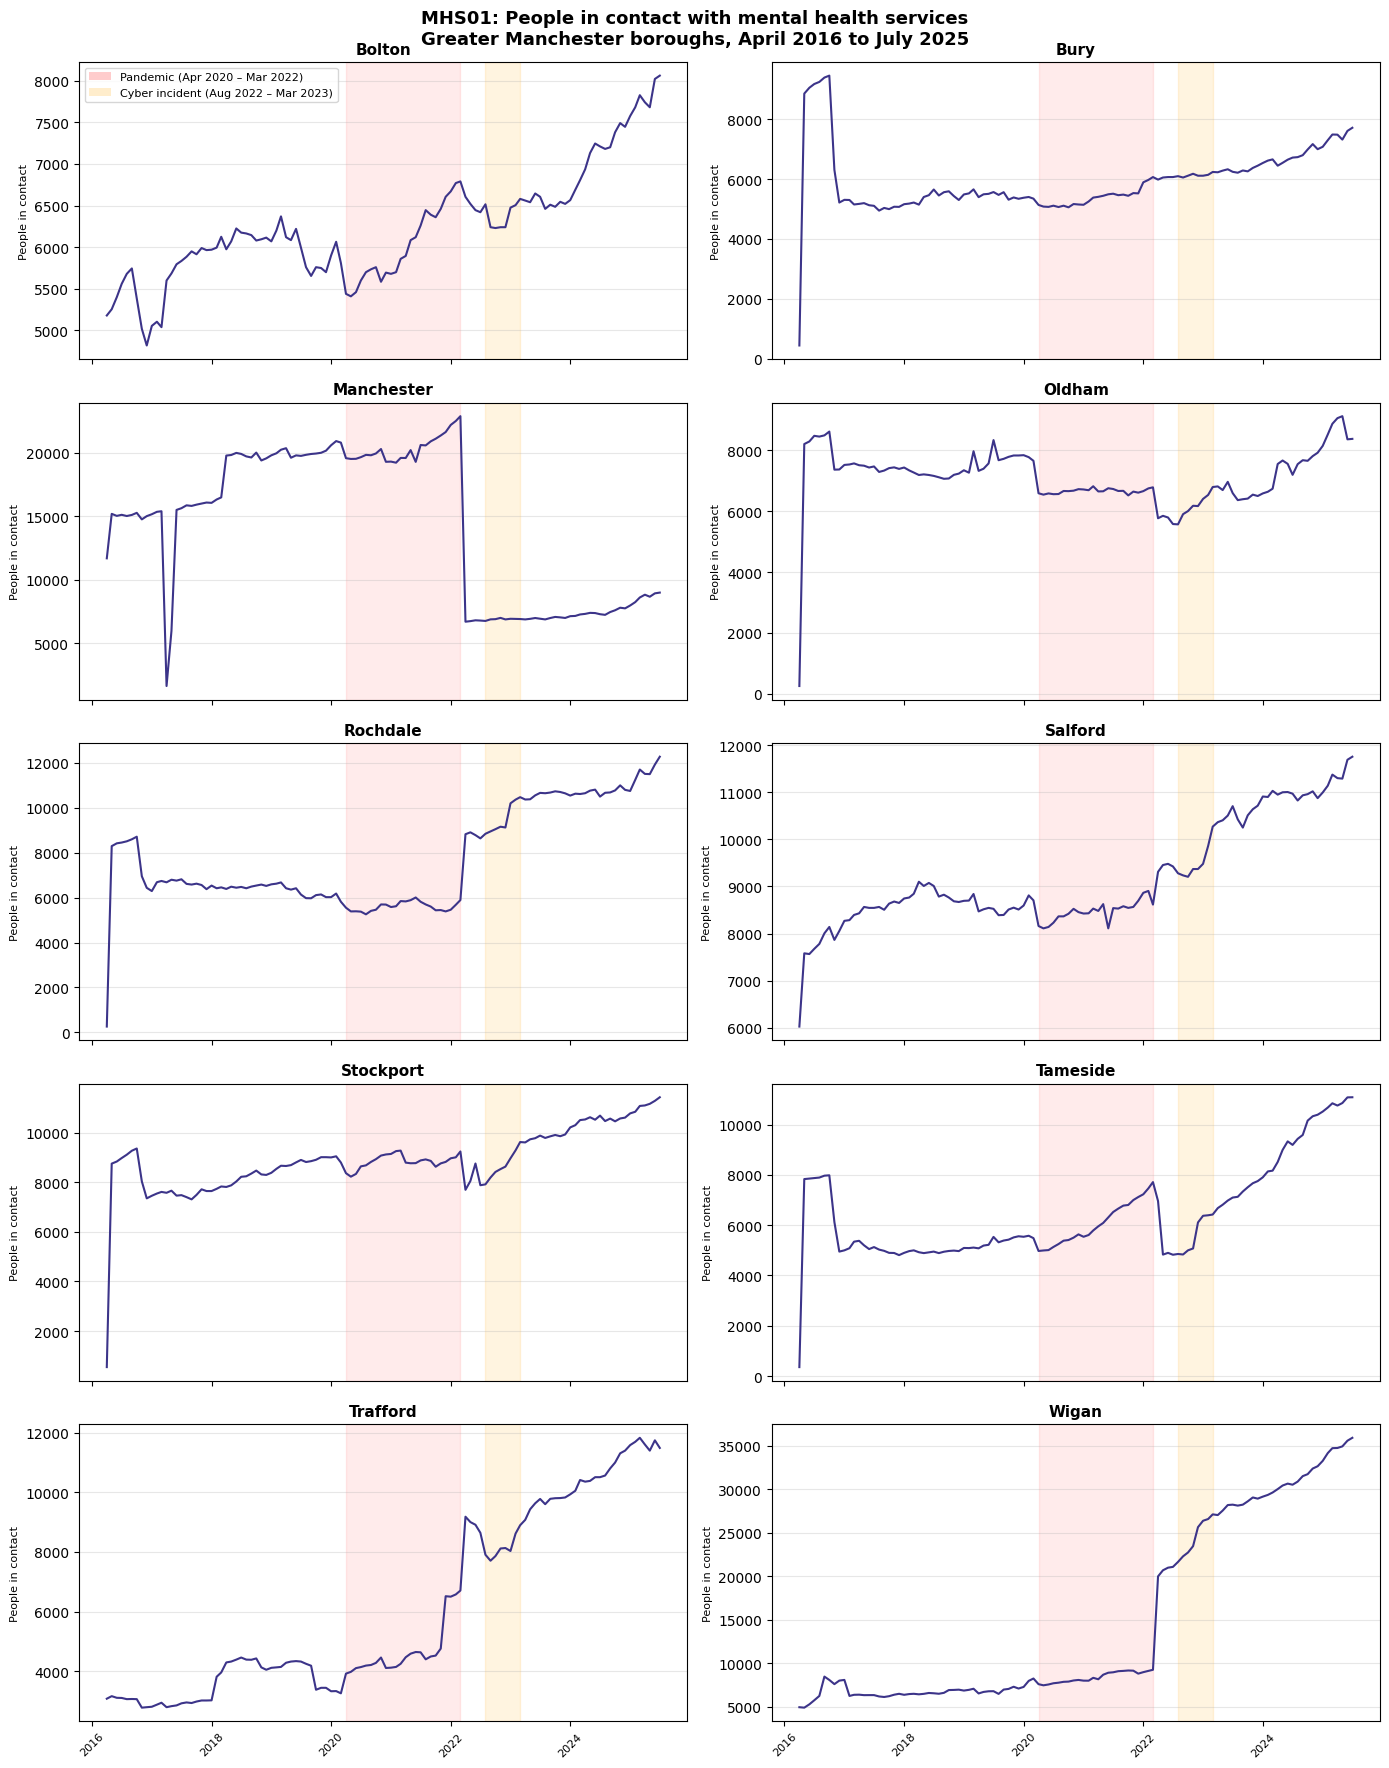

In [ ]:
%pip install -q matplotlib statsmodels

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

Path("data/plots").mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(5, 2, figsize=(14, 18), sharex=True)
axes = axes.flatten()

for i, borough in enumerate(sorted(df_master["borough"].unique())):
    df_b = df_master[df_master["borough"] == borough].sort_values("REPORTING_PERIOD_START")
    axes[i].plot(df_b["REPORTING_PERIOD_START"], df_b["people_in_contact"],
                 linewidth=1.5, color="#3C3489")
    axes[i].set_title(borough, fontsize=11, fontweight="bold")
    axes[i].set_ylabel("People in contact", fontsize=8)
    axes[i].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[i].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[i].tick_params(axis="x", rotation=45, labelsize=8)
    axes[i].grid(axis="y", alpha=0.3)
    axes[i].axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2022-03-01"),
                    alpha=0.08, color="red")
    axes[i].axvspan(pd.Timestamp("2022-08-01"), pd.Timestamp("2023-03-01"),
                    alpha=0.12, color="orange")

legend_elements = [
    Patch(facecolor="red",    alpha=0.2, label="Pandemic (Apr 2020 – Mar 2022)"),
    Patch(facecolor="orange", alpha=0.2, label="Cyber incident (Aug 2022 – Mar 2023)"),
]
axes[0].legend(handles=legend_elements, fontsize=8, loc="upper left")
fig.suptitle(
    "MHS01: People in contact with mental health services\n"
    "Greater Manchester boroughs, April 2016 to July 2025",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig("data/plots/mhs01_gm_boroughs.png", dpi=150, bbox_inches="tight")
plt.show()

### C2. Descriptive Statistics per Borough

Borough-level summary statistics for the target variable. The coefficient of variation (CV%) is included because it tells us how much month-to-month variability each series carries, high CV boroughs are harder to forecast and may need different model treatment. Manchester's elevated mean is expected and reflects the three-CCG summation for the pre-ICB period.


In [ ]:
stats = (
    df_master.dropna(subset=["people_in_contact"])
    .groupby("borough")["people_in_contact"]
    .agg(["mean", "std", "min", "max"]).round(0).astype(int)
)
stats["cv_pct"] = ((stats["std"] / stats["mean"]) * 100).round(1)
stats.columns = ["Mean", "Std Dev", "Min", "Max", "CV%"]
print("MHS01 descriptive statistics per borough (Apr 2016 - Jul 2025):")
print(stats.sort_values("Mean", ascending=False).to_string())

MHS01 descriptive statistics per borough (Apr 2016 - Jul 2025):
             Mean  Std Dev   Min    Max   CV%
borough                                      
Wigan       14913    10624  4925  35905  71.2
Manchester  14350     5927  1645  22875  41.3
Salford      9180     1124  6025  11755  12.2
Stockport    8890     1295   550  11425  14.6
Rochdale     7728     2241   260  12270  29.0
Oldham       7115      989   260   9115  13.9
Tameside     6452     1893   355  11090  29.3
Bolton       6238      673  4820   8060  10.8
Trafford     6063     3054  2780  11825  50.4
Bury         5950     1145   445   9450  19.2


### C3. Monthly Seasonality Profile

We plot the average referral count by calendar month across all boroughs to visually confirm the annual seasonal pattern. This is the empirical justification for setting `s=12` in the SARIMA seasonal specification. If the pattern were inconsistent across boroughs, some peaking in summer, others in winter, we would need to consider borough-specific seasonal orders. The chart should show a broadly consistent pattern, which is the assumption the modelling notebook builds on.


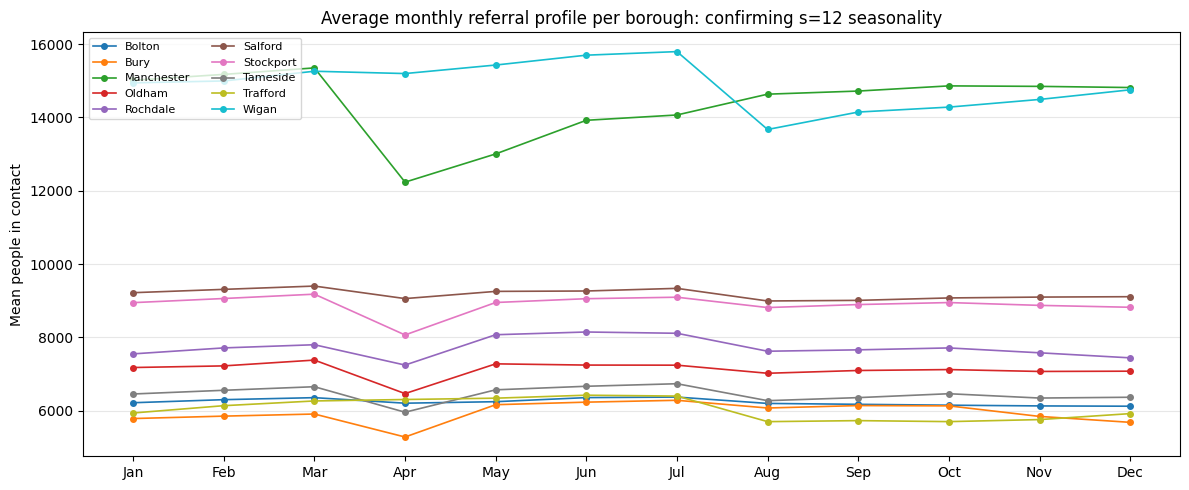

In [ ]:
import matplotlib.ticker as mticker

df_master["calendar_month"] = df_master["REPORTING_PERIOD_START"].dt.month
seasonal = (
    df_master.dropna(subset=["people_in_contact"])
    .groupby(["borough", "calendar_month"])["people_in_contact"]
    .mean().reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
for borough in sorted(seasonal["borough"].unique()):
    df_b = seasonal[seasonal["borough"] == borough].sort_values("calendar_month")
    ax.plot(df_b["calendar_month"], df_b["people_in_contact"],
            marker="o", linewidth=1.2, markersize=4, label=borough)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun",
                    "Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Average monthly referral profile per borough: confirming s=12 seasonality",
             fontsize=12)
ax.set_ylabel("Mean people in contact")
ax.legend(fontsize=8, ncol=2, loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("data/plots/mhs01_seasonality.png", dpi=150, bbox_inches="tight")
plt.show()

### C4. Augmented Dickey-Fuller Stationarity Tests

SARIMA requires a stationary time series, or a specified number of differences `d` to make it stationary. We run the ADF test per borough on the raw series, then re-test with first-order differencing for any non-stationary series.

> **Interpretation:** p-value < 0.05 → reject the null of a unit root → series is stationary at level → `d=0`. p-value ≥ 0.05 → unit root present → differencing required → `d=1`.

The `d` values determined here are passed directly into the SARIMA fitting in the modelling notebook. They are not estimated by `auto_arima`, they are fixed from this test, which is the methodologically correct approach when stationarity has been formally tested (Box et al., 2015).


In [ ]:
from statsmodels.tsa.stattools import adfuller

print("ADF stationarity test: raw series:")
print(f"{'Borough':<15} {'ADF Stat':>10} {'p-value':>10} {'Stationary?':>14}")
print("-" * 52)

adf_results: dict[str, dict] = {}
for borough in sorted(df_master["borough"].unique()):
    series = (
        df_master[df_master["borough"] == borough]
        .sort_values("REPORTING_PERIOD_START")["people_in_contact"].dropna()
    )
    result = adfuller(series, autolag="AIC")
    is_stat = result[1] < 0.05
    adf_results[borough] = {"adf_stat": result[0], "p_value": result[1], "stationary": is_stat}
    print(f"{borough:<15} {result[0]:>10.3f} {result[1]:>10.4f} "
          f"{'Yes' if is_stat else 'No: d≥1':>14}")

ADF stationarity test: raw series:
Borough           ADF Stat    p-value    Stationary?
----------------------------------------------------
Bolton               0.048     0.9623        No: d≥1
Bury                -4.268     0.0005            Yes
Manchester          -1.443     0.5613        No: d≥1
Oldham              -9.432     0.0000            Yes
Rochdale            -3.020     0.0331            Yes
Salford             -1.723     0.4192        No: d≥1
Stockport           -0.002     0.9584        No: d≥1
Tameside             0.172     0.9706        No: d≥1
Trafford             0.331     0.9787        No: d≥1
Wigan                0.890     0.9930        No: d≥1


In [ ]:
# First-order differencing check for non-stationary boroughs
non_stationary = [b for b, r in adf_results.items() if not r["stationary"]]

if not non_stationary:
    print("All boroughs stationary at level - SARIMA d=0 is appropriate.")
else:
    print(f"Non-stationary boroughs: {non_stationary}")
    print(f"\nADF after d=1 differencing:")
    print(f"{'Borough':<15} {'ADF Stat':>10} {'p-value':>10} {'Resolved?':>12}")
    print("-" * 50)
    for borough in sorted(non_stationary):
        series = (
            df_master[df_master["borough"] == borough]
            .sort_values("REPORTING_PERIOD_START")["people_in_contact"]
            .dropna().diff().dropna()
        )
        result = adfuller(series, autolag="AIC")
        resolved = result[1] < 0.05
        print(f"{borough:<15} {result[0]:>10.3f} {result[1]:>10.4f} "
              f"{'d=1 sufficient' if resolved else 'Needs d=2':>12}")
    print("\nConclusion: set d=1 in SARIMA for non-stationary boroughs.")

Non-stationary boroughs: ['Bolton', 'Manchester', 'Salford', 'Stockport', 'Tameside', 'Trafford', 'Wigan']

ADF after d=1 differencing:
Borough           ADF Stat    p-value    Resolved?
--------------------------------------------------
Bolton              -3.958     0.0016 d=1 sufficient
Manchester         -10.976     0.0000 d=1 sufficient
Salford            -14.532     0.0000 d=1 sufficient
Stockport           -8.305     0.0000 d=1 sufficient
Tameside           -22.034     0.0000 d=1 sufficient
Trafford            -9.917     0.0000 d=1 sufficient
Wigan               -9.767     0.0000 d=1 sufficient

Conclusion: set d=1 in SARIMA for non-stationary boroughs.


## Next Step: Exploratory Data Analysis

The EDA notebook will load `mindcastgm_master.parquet` and run the full exploratory analysis: missing data audit, outlier detection, STL decomposition, stationarity confirmation, the central hypothesis lag correlation tests, and the train/validation/test split visualisation. The EDA is where we find out whether the wellbeing features carry genuine signal before any model sees the data.


---

## References

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5th ed.). Wiley.

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, *30*, 4765-4774.

Ministry of Housing, Communities & Local Government. (2019). *English indices of deprivation 2019*. https://www.gov.uk/government/statistics/english-indices-of-deprivation-2019

NHS England. (2022). *Integrated care boards, NHS organisational change*. https://www.england.nhs.uk/integratedcare/

NHS England. (2023). *Advanced cyber incident, reporting impact*. NHS Digital. https://digital.nhs.uk/news/2022/advanced-cyber-attack

NHS England. (2025). *Mental Health Services Dataset (MHSDS) monthly time series, selected measures, April 2016 to July 2025* [Data set]. https://digital.nhs.uk/data-and-information/publications/statistical/mental-health-services-monthly-statistics

Office for National Statistics. (2023). *Personal well-being in the UK: April 2022 to March 2023* [Data set]. https://www.ons.gov.uk/peoplepopulationandcommunity/wellbeing/bulletins/measuringnationalwellbeing/april2022tomarch2023

Office for National Statistics. (2024). *Mid-year population estimates, England and Wales: mid-2011 to mid-2024* [Data set]. https://www.ons.gov.uk/peoplepopulationandcommunity/populationandmigration/populationestimates
